# Sesión 4 · De la imagen al vector: descriptores y PCA
**Unidad 4. Descripción y representación de imágenes digitales** · Procesamiento Digital de Imágenes · Maestría en Ciencia de Datos e Información · INFOTEC · 2027-1

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/egonzalez1989/pdi-mcdi/blob/main/sesiones/S4_Descriptores_y_representacion.ipynb)

**Objetivo de la sesión.** Construir una matriz de diseño con descriptores de forma, textura y color y explorarla con PCA.

**Clase síncrona:** jueves 11 de marzo de 2027, de 11:00 a 13:00 hrs. · **Sesiones opcionales de la unidad** (12:00 a 13:00 hrs.): jueves 1 de abril (dudas de la actividad 4A); jueves 8 de abril (retroalimentación de 4A y defensas orales).

**Agenda (120 min)**
1. Forma: regionprops y momentos de Hu (20 min)
2. Textura: GLCM y LBP sobre parches de materiales (25 min)
3. Color y descriptores locales (HOG, ORB) (20 min)
4. Matriz de diseño estandarizada y PCA (20 min)
5. t-SNE y lectura crítica de la separabilidad (15 min)
6. Actividad 4A y dudas (20 min)

**Cómo usar este cuaderno.** Ejecuta las celdas en orden (`Shift + Enter`). Las secciones marcadas con 🧪 son pausas para que experimentes cambiando parámetros; las marcadas con 💬 son preguntas para discutir en la sesión. Al final encontrarás la conexión con la actividad **4A**.

In [1]:
# Configuración del entorno. En Google Colab todas estas bibliotecas ya vienen instaladas.
import sys, platform
import numpy as np
import matplotlib.pyplot as plt
import cv2
import skimage
from skimage import data

plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 10, "image.cmap": "gray"})
np.random.seed(42)

def mostrar(imagenes, titulos=None, cols=None, cmap="gray", tam=3.2, ejes=False):
    """Muestra una lista de imágenes en una cuadrícula. Las imágenes a color deben estar en RGB."""
    if not isinstance(imagenes, (list, tuple)):
        imagenes = [imagenes]
    n = len(imagenes)
    cols = cols or min(n, 4)
    filas = int(np.ceil(n / cols))
    fig, axs = plt.subplots(filas, cols, figsize=(tam * cols, tam * filas), squeeze=False)
    for i, ax in enumerate(axs.flat):
        if i < n:
            im = imagenes[i]
            ax.imshow(im, cmap=None if im.ndim == 3 else cmap)
            if titulos:
                ax.set_title(titulos[i])
        if not ejes or i >= n:
            ax.axis("off")
    plt.tight_layout()
    plt.show()

print(f"Python {platform.python_version()} | NumPy {np.__version__} | OpenCV {cv2.__version__} | scikit-image {skimage.__version__}")

import pandas as pd
from scipy import ndimage as ndi
from scipy.stats import skew
from skimage import measure, feature, color, filters
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.feature_selection import f_classif

Python 3.12.15 | NumPy 2.5.4 | OpenCV 5.0.0 | scikit-image 0.26.0


## 1. Del píxel al vector
Un modelo de aprendizaje automático espera una **matriz de diseño** $X \in \mathbb{R}^{n \times p}$: $n$ muestras (imágenes u objetos) y $p$ características. Un buen descriptor es:
- **Discriminante:** distingue las clases.
- **Invariante** a lo que no importa (posición, rotación, escala, iluminación).
- **Compacto y robusto** al ruido.

## 2. Descriptores de forma
Partimos de la segmentación de la sesión 3: cada moneda es una región.

In [2]:
monedas = data.coins()
suave = cv2.GaussianBlur(monedas, (5, 5), 0)
mascara = suave > filters.threshold_local(suave, 95, offset=-8)
mascara = ndi.binary_fill_holes(cv2.morphologyEx(mascara.astype(np.uint8), cv2.MORPH_CLOSE, np.ones((5, 5), np.uint8)))
mascara = cv2.morphologyEx(mascara.astype(np.uint8), cv2.MORPH_OPEN, np.ones((7, 7), np.uint8))
etiquetas = measure.label(mascara)

props = measure.regionprops_table(
    etiquetas, intensity_image=monedas,
    properties=["label", "area", "perimeter", "eccentricity", "solidity", "intensity_mean", "centroid"])
forma = pd.DataFrame(props).query("area > 200").reset_index(drop=True)
forma["circularidad"] = 4 * np.pi * forma.area / forma.perimeter ** 2      # 1 = círculo perfecto
display(forma.drop(columns=["centroid-0", "centroid-1"]).head(8).round(3))

,label,area,perimeter,eccentricity,solidity,intensity_mean,circularidad
0,5,2608.0,188.267,0.299,0.984,156.337,0.925
1,6,1645.0,148.711,0.333,0.981,169.270,0.935
2,7,1590.0,147.054,0.366,0.979,158.084,0.924
3,8,1203.0,128.811,0.396,0.969,154.637,0.911
4,9,1352.0,135.054,0.535,0.981,167.621,0.931
5,10,1111.0,122.912,0.437,0.976,183.869,0.924
6,12,1928.0,163.296,0.331,0.978,158.211,0.909
7,13,1335.0,136.225,0.325,0.972,188.472,0.904


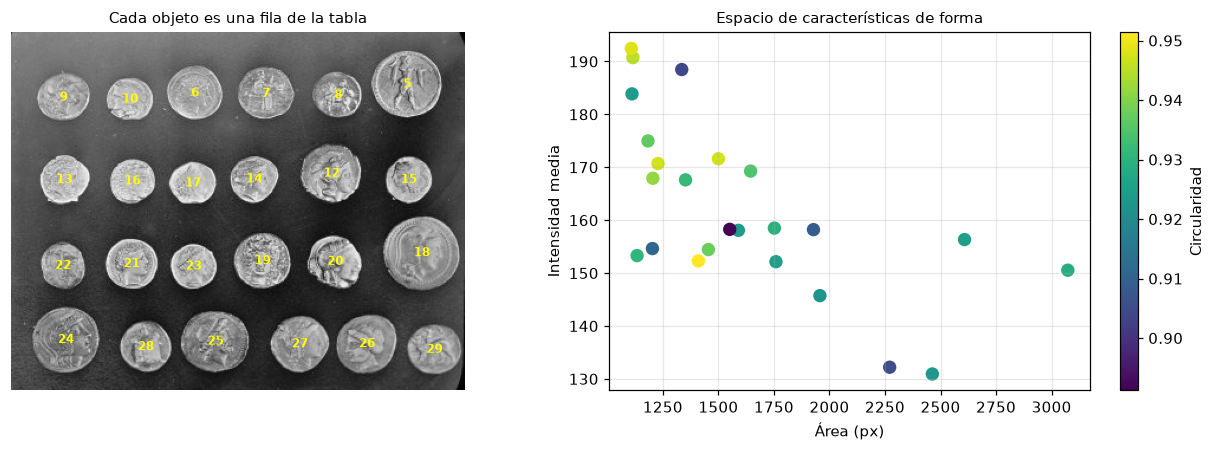

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
ax[0].imshow(monedas, cmap="gray"); ax[0].axis("off"); ax[0].set_title("Cada objeto es una fila de la tabla")
for _, f in forma.iterrows():
    ax[0].text(f["centroid-1"], f["centroid-0"], int(f.label), color="yellow", ha="center", va="center", fontsize=8, weight="bold")
sc = ax[1].scatter(forma.area, forma.intensity_mean, c=forma.circularidad, cmap="viridis", s=60)
ax[1].set_xlabel("Área (px)"); ax[1].set_ylabel("Intensidad media"); plt.colorbar(sc, label="Circularidad")
ax[1].set_title("Espacio de características de forma"); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

### Momentos invariantes de Hu
Siete combinaciones de momentos centrales normalizados, **invariantes a traslación, escala y rotación** (Hu, 1962). Como varían en órdenes de magnitud, se usan en escala logarítmica: $-\mathrm{sign}(h)\log_{10}|h|$.

,Hu1,Hu2,Hu3,Hu4,Hu5,Hu6,Hu7
Elipse,0.66,1.65,8.71,9.58,18.91,10.85,-18.85
Rotada 40°,0.66,1.66,7.68,8.87,-17.15,-9.71,-18.72
Escalada 0.6,0.66,1.65,7.08,7.65,15.02,8.48,-26.39
Cuadrado,0.78,0.00,0.00,0.00,0.00,0.00,0.00


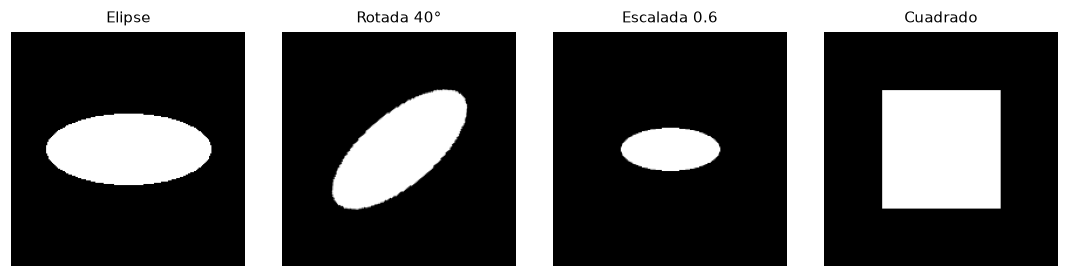

In [4]:
lienzo = np.zeros((200, 200), np.uint8)
cv2.ellipse(lienzo, (100, 100), (70, 30), 0, 0, 360, 255, -1)
variantes = {
    "Elipse": lienzo,
    "Rotada 40°": cv2.warpAffine(lienzo, cv2.getRotationMatrix2D((100, 100), 40, 1), (200, 200)),
    "Escalada 0.6": cv2.warpAffine(lienzo, cv2.getRotationMatrix2D((100, 100), 0, 0.6), (200, 200)),
    "Cuadrado": cv2.rectangle(np.zeros((200, 200), np.uint8), (50, 50), (150, 150), 255, -1),
}
def hu_log(m):
    h = cv2.HuMoments(cv2.moments(m, binaryImage=True)).ravel()
    return -np.sign(h) * np.log10(np.abs(h) + 1e-30)
display(pd.DataFrame({k: hu_log(v) for k, v in variantes.items()}, index=[f"Hu{i}" for i in range(1, 8)]).round(2).T)
mostrar(list(variantes.values()), list(variantes.keys()), tam=2.5)

Observa que la elipse rotada y escalada conserva prácticamente los mismos momentos, mientras que el cuadrado cambia: **invarianza + discriminación**.

## 3. Descriptores de textura
Construimos un pequeño conjunto de datos de **parches de 64 × 64** de tres materiales (ladrillo, pasto, grava), como lo haríamos en inspección de superficies o en análisis de suelos. Agregamos variaciones de brillo para que no sea trivial.

120 parches de 64×64 | clases: {np.str_('grava'): np.int64(40), np.str_('ladrillo'): np.int64(40), np.str_('pasto'): np.int64(40)}


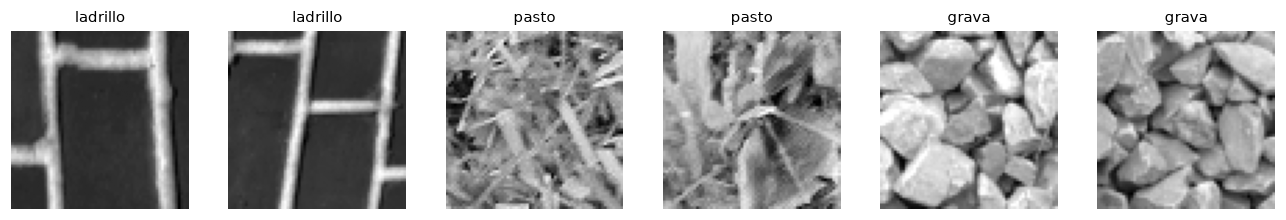

In [5]:
texturas = {"ladrillo": data.brick(), "pasto": data.grass(), "grava": data.gravel()}
P = 64
rng = np.random.default_rng(0)
parches, clases, fuente = [], [], []
for nombre, im in texturas.items():
    h, w = im.shape
    for _ in range(40):
        y, x = rng.integers(0, h - P), rng.integers(0, w - P)
        p = im[y:y + P, x:x + P].astype(np.float32)
        p = np.clip(p * rng.uniform(0.7, 1.3) + rng.uniform(-25, 25), 0, 255).astype(np.uint8)
        parches.append(p); clases.append(nombre); fuente.append("superior" if y < h // 2 else "inferior")
clases = np.array(clases)
print(f"{len(parches)} parches de {P}×{P} | clases: {dict(zip(*np.unique(clases, return_counts=True)))}")
mostrar([parches[i] for i in [0, 1, 40, 41, 80, 81]], [clases[i] for i in [0, 1, 40, 41, 80, 81]], cols=6, tam=2)

### Matriz de co-ocurrencia de niveles de gris (GLCM)
$P_{d,\theta}(i, j)$ cuenta cuántas veces un píxel con nivel $i$ tiene un vecino con nivel $j$ a distancia $d$ y ángulo $\theta$. De ella Haralick (1973) define propiedades como **contraste**, **homogeneidad**, **energía** y **correlación**.

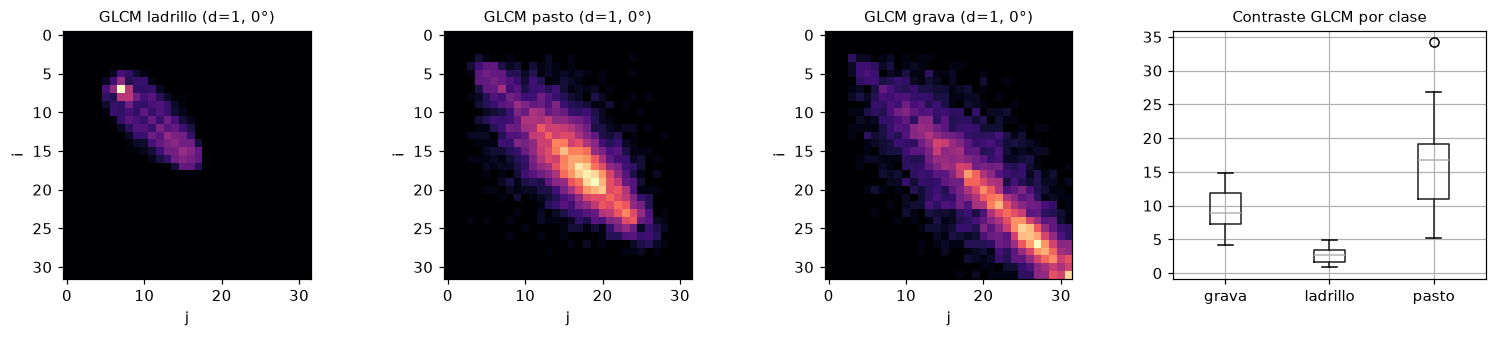

In [6]:
def glcm_features(p, distancias=(1, 3), angulos=(0, np.pi/4, np.pi/2, 3*np.pi/4), niveles=32):
    q = (p // (256 // niveles)).astype(np.uint8)         # cuantizamos para que la matriz no sea dispersa
    g = feature.graycomatrix(q, distancias, angulos, levels=niveles, symmetric=True, normed=True)
    props = ["contrast", "homogeneity", "energy", "correlation"]
    # Promediamos sobre ángulos → invarianza aproximada a rotación
    return {f"glcm_{pr}_d{d}": feature.graycoprops(g, pr)[i].mean() for pr in props for i, d in enumerate(distancias)}

ejemplo = parches[0] // 8
g = feature.graycomatrix(ejemplo, [1], [0], levels=32, symmetric=True, normed=True)[:, :, 0, 0]
fig, ax = plt.subplots(1, 4, figsize=(14, 3.3))
for k, idx in enumerate([0, 40, 80]):
    gi = feature.graycomatrix(parches[idx] // 8, [1], [0], levels=32, symmetric=True, normed=True)[:, :, 0, 0]
    ax[k].imshow(np.log1p(gi * 1000), cmap="magma"); ax[k].set_title(f"GLCM {clases[idx]} (d=1, 0°)"); ax[k].set_xlabel("j"); ax[k].set_ylabel("i")
tex = pd.DataFrame([glcm_features(p) for p in parches]); tex["clase"] = clases
tex.boxplot(column="glcm_contrast_d1", by="clase", ax=ax[3]); ax[3].set_title("Contraste GLCM por clase"); ax[3].set_xlabel("")
plt.suptitle(""); plt.tight_layout(); plt.show()

### Patrones binarios locales (LBP)
Cada píxel se compara con sus $P$ vecinos en un círculo de radio $R$ y se codifica como un número binario. El histograma de códigos **uniformes** es robusto a cambios monotónicos de iluminación (Ojala et al., 2002).

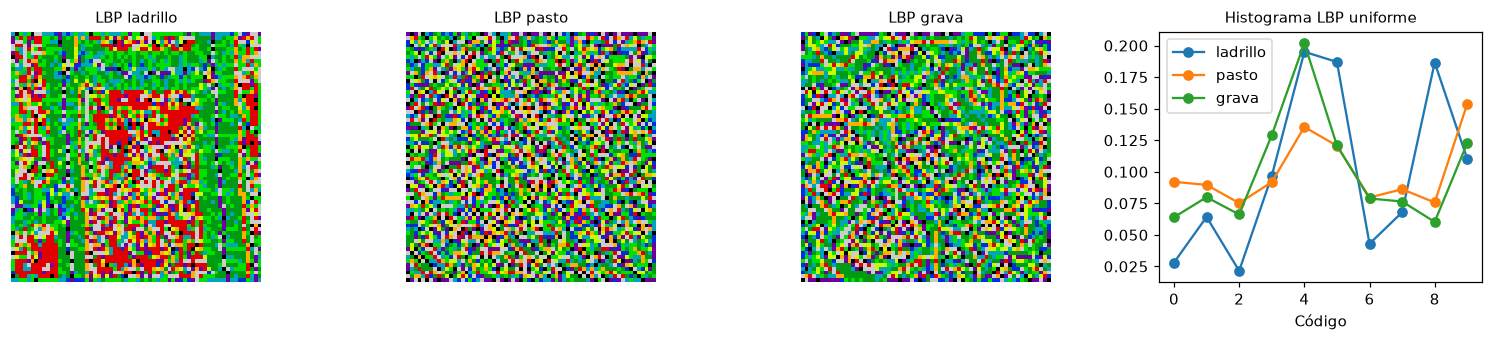

In [7]:
def lbp_hist(p, P_=8, R=1):
    lbp = feature.local_binary_pattern(p, P_, R, method="uniform")
    h, _ = np.histogram(lbp, bins=np.arange(P_ + 3), density=True)
    return {f"lbp_{i}": v for i, v in enumerate(h)}

fig, ax = plt.subplots(1, 4, figsize=(14, 3.2))
for k, idx in enumerate([0, 40, 80]):
    ax[k].imshow(feature.local_binary_pattern(parches[idx], 8, 1, "uniform"), cmap="nipy_spectral"); ax[k].set_title(f"LBP {clases[idx]}"); ax[k].axis("off")
    ax[3].plot(list(lbp_hist(parches[idx]).values()), marker="o", label=clases[idx])
ax[3].legend(); ax[3].set_title("Histograma LBP uniforme"); ax[3].set_xlabel("Código")
plt.tight_layout(); plt.show()

## 4. Descriptores de color: momentos de color
Para cada canal: media (1.er momento), desviación estándar (2.º) y asimetría (3.er). Nueve números resumen la distribución de color de una imagen (Keen, 2005). Usamos HSV para separar tono e iluminación.

In [8]:
def momentos_color(rgb, espacio=cv2.COLOR_RGB2HSV):
    x = cv2.cvtColor(rgb, espacio).reshape(-1, 3).astype(np.float32)
    nombres = "HSV" if espacio == cv2.COLOR_RGB2HSV else "Lab"
    out = {}
    for c, n in enumerate(nombres):
        out[f"{n}_media"], out[f"{n}_std"], out[f"{n}_asim"] = x[:, c].mean(), x[:, c].std(), skew(x[:, c])
    return out

imgs = {"Astronauta": data.astronaut(), "Café": data.coffee(), "Gato": data.chelsea(), "Cohete": data.rocket()}
display(pd.DataFrame({k: momentos_color(v) for k, v in imgs.items()}).T.round(1))

,H_media,H_std,H_asim,S_media,S_std,S_asim,V_media,V_std,V_asim
Astronauta,38.900002,59.500000,1.5,90.900002,88.099998,0.5,143.000000,81.300003,-0.6
Café,10.500000,12.300000,9.9,184.899994,54.500000,-1.1,158.600006,63.000000,-0.9
Gato,13.500000,18.299999,8.4,110.099998,44.500000,0.3,147.699997,32.200001,-1.1
Cohete,101.300003,32.599998,-1.9,121.900002,42.400002,-0.5,87.599998,34.200001,1.2


## 5. Descriptores locales: HOG y ORB
- **HOG** (Dalal y Triggs, 2005): histogramas de orientaciones del gradiente en celdas; captura la *forma* global. Fue el estado del arte en detección de personas antes del aprendizaje profundo.
- **ORB** (Rublee et al., 2011): detecta **puntos clave** y los describe con un código binario; permite **emparejar** la misma escena aunque cambie la rotación o la escala (alineación de imágenes, panorámicas, búsqueda de duplicados).

Dimensión del vector HOG: (34596,)


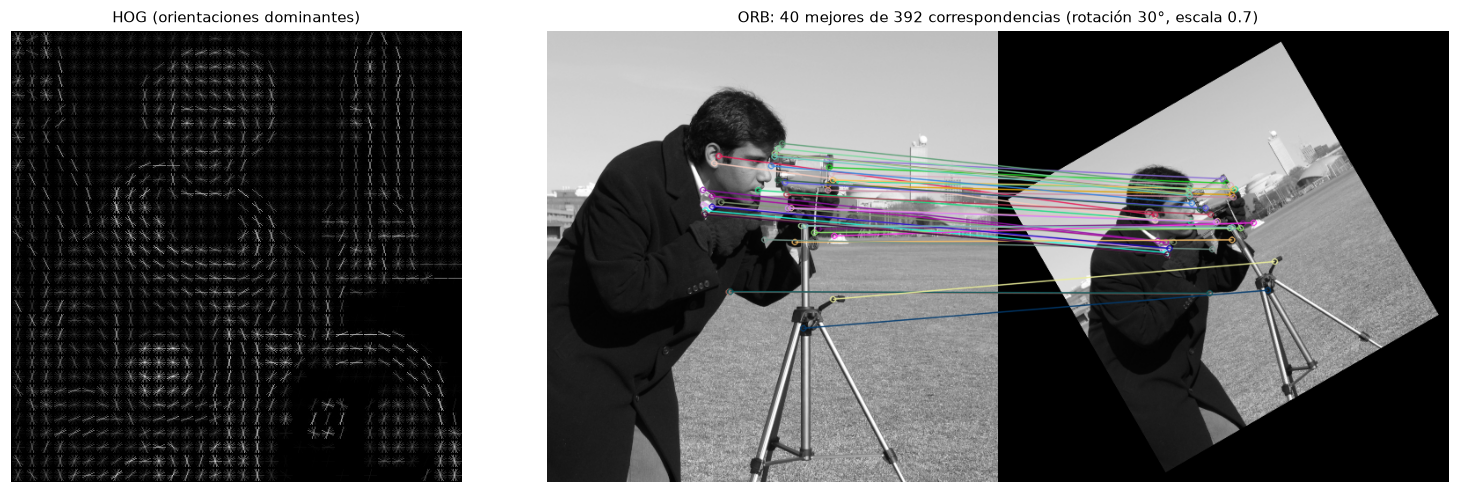

In [9]:
astro = color.rgb2gray(data.astronaut())
vec_hog, vis_hog = feature.hog(astro, orientations=9, pixels_per_cell=(16, 16), cells_per_block=(2, 2), visualize=True)
print("Dimensión del vector HOG:", vec_hog.shape)

cam = data.camera()
h, w = cam.shape
M = cv2.getRotationMatrix2D((w / 2, h / 2), 30, 0.7)
cam2 = cv2.warpAffine(cam, M, (w, h))
orb = cv2.ORB_create(nfeatures=800)
kp1, d1 = orb.detectAndCompute(cam, None)
kp2, d2 = orb.detectAndCompute(cam2, None)
matches = sorted(cv2.BFMatcher(cv2.NORM_HAMMING, crossCheck=True).match(d1, d2), key=lambda m: m.distance)
vis = cv2.drawMatches(cam, kp1, cam2, kp2, matches[:40], None, flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [1, 2]})
ax[0].imshow(vis_hog ** 0.5, cmap="gray"); ax[0].set_title("HOG (orientaciones dominantes)"); ax[0].axis("off")
ax[1].imshow(vis); ax[1].set_title(f"ORB: 40 mejores de {len(matches)} correspondencias (rotación 30°, escala 0.7)"); ax[1].axis("off")
plt.tight_layout(); plt.show()

## 6. Matriz de diseño y reducción de dimensión
Integramos textura (GLCM + LBP) y estadísticos de intensidad para los 120 parches. **Siempre estandariza** antes de PCA: las características tienen escalas muy distintas.

In [10]:
def descriptor(p):
    d = {}
    d.update(glcm_features(p))
    d.update(lbp_hist(p))
    d.update({"int_media": p.mean(), "int_std": p.std(), "int_asim": skew(p.ravel())})
    return d

X_df = pd.DataFrame([descriptor(p) for p in parches])
X_df.insert(0, "clase", clases)
print("Matriz de diseño:", X_df.shape, "| faltantes:", X_df.isna().sum().sum())
display(X_df.groupby("clase").mean().T.head(8).round(3))
X = StandardScaler().fit_transform(X_df.drop(columns="clase"))

Matriz de diseño: (120, 22) | faltantes: 0


clase,grava,ladrillo,pasto
glcm_contrast_d1,9.441,2.581,16.197
glcm_contrast_d3,26.321,9.652,32.537
glcm_homogeneity_d1,0.436,0.765,0.356
glcm_homogeneity_d3,0.286,0.687,0.245
glcm_energy_d1,0.098,0.527,0.082
glcm_energy_d3,0.076,0.491,0.069
glcm_correlation_d1,0.807,0.891,0.659
glcm_correlation_d3,0.462,0.598,0.314


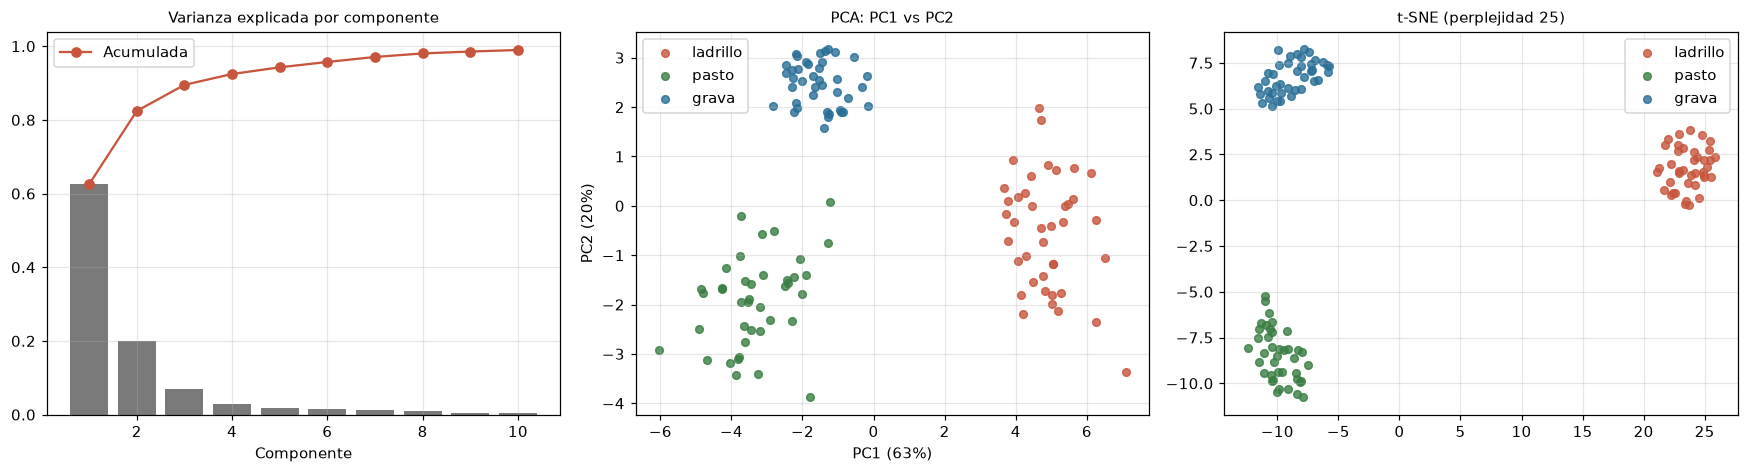

In [11]:
pca = PCA().fit(X)
Z = pca.transform(X)
tsne = TSNE(n_components=2, perplexity=25, random_state=0, init="pca").fit_transform(X)
colores = {"ladrillo": "#c8553d", "pasto": "#3a7d44", "grava": "#2a6f97"}

fig, ax = plt.subplots(1, 3, figsize=(16, 4.4))
ax[0].bar(range(1, 11), pca.explained_variance_ratio_[:10], color="#7a7a7a")
ax[0].plot(range(1, 11), np.cumsum(pca.explained_variance_ratio_[:10]), "o-", color="#c8553d", label="Acumulada")
ax[0].set_title("Varianza explicada por componente"); ax[0].set_xlabel("Componente"); ax[0].legend(); ax[0].grid(alpha=.3)
for c, col in colores.items():
    m = clases == c
    ax[1].scatter(Z[m, 0], Z[m, 1], c=col, label=c, s=25, alpha=.8)
    ax[2].scatter(tsne[m, 0], tsne[m, 1], c=col, label=c, s=25, alpha=.8)
ax[1].set_title("PCA: PC1 vs PC2"); ax[1].set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%})"); ax[1].set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%})")
ax[2].set_title("t-SNE (perplejidad 25)")
for a in ax[1:]: a.legend(); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

### ¿Qué características separan mejor las clases?
La prueba **ANOVA F** compara la varianza entre clases con la varianza dentro de cada clase, característica por característica. Es un primer filtro rápido (no sustituye a un modelo).

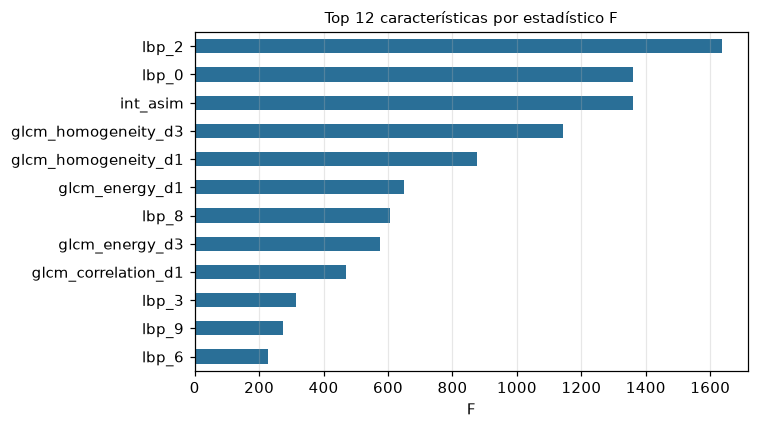

In [12]:
F, pval = f_classif(X, clases)
ranking = pd.Series(F, index=X_df.columns[1:]).sort_values(ascending=True).tail(12)
ranking.plot.barh(figsize=(7, 4), color="#2a6f97"); plt.title("Top 12 características por estadístico F"); plt.xlabel("F")
plt.grid(axis="x", alpha=.3); plt.tight_layout(); plt.show()

💬 **Discusión.** Si las características de intensidad (`int_media`) aparecieran arriba del ranking, ¿sería una buena noticia? Recuerda que alteramos el brillo al azar: un descriptor robusto **no** debería depender de él.

## 7. Puente a la Unidad 5: representaciones aprendidas
Las redes convolucionales preentrenadas producen **embeddings** (por ejemplo, 512 números en ResNet-18) que suelen separar las clases mejor que los descriptores diseñados a mano. En la siguiente sesión los compararemos con rigor.

## 8. Resumen y conexión con la actividad 4A
| Familia | Descriptores | Invarianzas típicas |
|---|---|---|
| Forma | área, perímetro, circularidad, excentricidad, Hu | traslación, rotación, escala (Hu) |
| Textura | GLCM (Haralick), LBP | iluminación monotónica (LBP), rotación (promedio de ángulos) |
| Color | histogramas, momentos de color | depende del espacio (HSV/Lab) |
| Local | HOG, ORB | ORB: rotación y escala |

**Actividad 4A. Descriptores de textura, forma y color con reducción de dimensión** (25 puntos, entrega: domingo 4 de abril de 2027). Usa la plantilla `4A_Plantilla_Descriptores.ipynb`: combina textura, color y forma, estandariza y explora con PCA (puedes usar los parches de `datos/texturas`).